(3448, 3)
label
neutral     2141
positive     887
negative     420
Name: count, dtype: int64


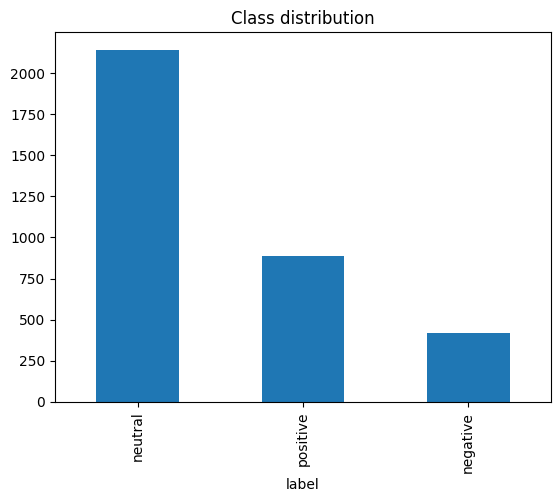

In [ ]:
# Student: Md Firoz Chowdhury, HAMK
# Exercise: 4.4.5

#1. Load data and check class distribution
import re, zipfile, urllib.request, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

URL = "https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip"
urllib.request.urlretrieve(URL, "fpb.zip")
with zipfile.ZipFile("fpb.zip") as z:
    name = [n for n in z.namelist() if n.endswith("Sentences_75Agree.txt")][0]
    rows = [l.rsplit("@", 1) for l in z.read(name).decode("latin-1").splitlines() if "@" in l]
df = pd.DataFrame(rows, columns=["text", "label"]).drop_duplicates("text")

LABELS = ["negative", "neutral", "positive"]
df["y"] = df["label"].str.strip().map({l: i for i, l in enumerate(LABELS)})
print(df.shape); print(df["label"].value_counts())
df["label"].value_counts().plot.bar(title="Class distribution"); plt.show()

In [2]:
# 2. Clean text and split 70/15/15
def clean(s):
    s = s.lower()
    s = re.sub(r"\d+([.,]\d+)*", " <num> ", s)
    s = re.sub(r"[^a-z<>%\s']", " ", s)
    return re.sub(r"\s+", " ", s).strip()
df["clean"] = df["text"].apply(clean)

train_df, tmp = train_test_split(df, test_size=0.3, stratify=df.y, random_state=42)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp.y, random_state=42)
y_train, y_val, y_test = train_df.y.values, val_df.y.values, test_df.y.values

In [3]:
#3. Tokenize, pad and train the LSTM
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

MAX_LEN = 50
tok = layers.TextVectorization(output_sequence_length=MAX_LEN, standardize=None)
tok.adapt(train_df["clean"].values)                # vocabulary from training data only
X_train, X_val, X_test = (tok(d["clean"].values) for d in (train_df, val_df, test_df))

lstm = keras.Sequential([
    layers.Embedding(tok.vocabulary_size(), 128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.4),
    layers.Dense(3, activation="softmax")])
lstm.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])

cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=y_train)))
lstm.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=32, class_weight=cw,
         callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

lstm_pred = lstm.predict(X_test).argmax(1)
print("LSTM  acc:", accuracy_score(y_test, lstm_pred), " macro-F1:", f1_score(y_test, lstm_pred, average="macro"))
print(classification_report(y_test, lstm_pred, target_names=LABELS))

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.1.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


Epoch 1/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.6092 - loss: 0.9662 - val_accuracy: 0.6654 - val_loss: 0.7436
Epoch 2/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.8384 - loss: 0.5298 - val_accuracy: 0.7950 - val_loss: 0.5316
Epoch 3/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9432 - loss: 0.2332 - val_accuracy: 0.8027 - val_loss: 0.5952
Epoch 4/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9648 - loss: 0.1602 - val_accuracy: 0.7969 - val_loss: 0.6741
Epoch 5/15
76/76 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.9814 - loss: 0.0921 - val_accuracy: 0.8085 - val_loss: 0.7172
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step
LSTM  acc: 0.803088803088803  macro-F1: 0.7439428296098457
              precision    recall  f1-score   support

    negative       0.73      0.59      0.65        63
     neutral       0.89      0.86      0.87       322
    positive       0.65      0.77      0.71       133

    accuracy                           0.80     

In [6]:
#4. Fine-tune DistilBERT
%pip install torch transformers
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

dev = "cuda" if torch.cuda.is_available() else "cpu"
NAME = "distilbert-base-uncased"
btok = AutoTokenizer.from_pretrained(NAME)
bert = AutoModelForSequenceClassification.from_pretrained(NAME, num_labels=3).to(dev)

def loader(d, shuffle):
    e = btok(list(d.text), padding="max_length", truncation=True, max_length=64, return_tensors="pt")
    return DataLoader(TensorDataset(e.input_ids, e.attention_mask, torch.tensor(d.y.values)), batch_size=16, shuffle=shuffle)
train_dl, val_dl, test_dl = loader(train_df, True), loader(val_df, False), loader(test_df, False)

@torch.no_grad()
def predict(dl):
    bert.eval()
    return torch.cat([bert(input_ids=i.to(dev), attention_mask=m.to(dev)).logits.argmax(-1).cpu() for i, m, _ in dl]).numpy()

opt = torch.optim.AdamW(bert.parameters(), lr=2e-5)
for epoch in range(3):
    bert.train()
    for i, m, y in train_dl:
        loss = bert(input_ids=i.to(dev), attention_mask=m.to(dev), labels=y.to(dev)).loss
        loss.backward(); opt.step(); opt.zero_grad()
    print(f"epoch {epoch+1} val macro-F1:", f1_score(y_val, predict(val_dl), average="macro"))

bert_pred = predict(test_dl)
print("BERT  acc:", accuracy_score(y_test, bert_pred), " macro-F1:", f1_score(y_test, bert_pred, average="macro"))
print(classification_report(y_test, bert_pred, target_names=LABELS))

Note: you may need to restart the kernel to use updated packages.


'DOSKEY' is not recognized as an internal or external command,
operable program or batch file.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1 val macro-F1: 0.9222228558953679
epoch 2 val macro-F1: 0.8993956952497643
epoch 3 val macro-F1: 0.933538138353633
BERT  acc: 0.9247104247104247  macro-F1: 0.9044699014014862
              precision    recall  f1-score   support

    negative       0.92      0.87      0.89        63
     neutral       0.93      0.98      0.95       322
    positive       0.91      0.83      0.87       133

    accuracy                           0.92       518
   macro avg       0.92      0.89      0.90       518
weighted avg       0.92      0.92      0.92       518



            accuracy  macro F1
LSTM           0.803     0.744
DistilBERT     0.925     0.904


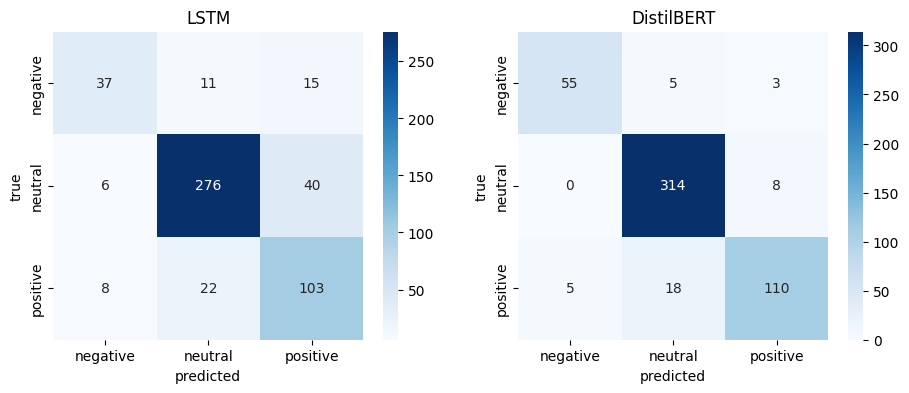

In [7]:
#5. Compare the metrics and show the confusion matrices
print(pd.DataFrame({
    "accuracy": [accuracy_score(y_test, p) for p in (lstm_pred, bert_pred)],
    "macro F1": [f1_score(y_test, p, average="macro") for p in (lstm_pred, bert_pred)]},
    index=["LSTM", "DistilBERT"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (n, p) in zip(ax, [("LSTM", lstm_pred), ("DistilBERT", bert_pred)]):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, ax=a)
    a.set(title=n, xlabel="predicted", ylabel="true")
plt.show()